# CEUB - Centro Universitário de Brasília
## Disciplina: Fundamentos de Big Data
### Professor: Klayton R. Castro
### Avaliação 01 – Prática: Questão 4 (Ingestão de Datasets no MinIO)

---

### Enunciado da Questão 4 (Valor: 3,5 pontos)
> Com base no Lab do MinIO, realize a ingestão dos datasets oficiais de exemplo do MongoDB em um *Data Lake*, utilizando armazenamento de objetos compatível com a API S3.
> 
> **a) Obtenção e restauração dos datasets.** Faça o download do arquivo `sampledata.archive`, restaure os bancos de dados no MongoDB utilizando `mongorestore` e apresente a quantidade de documentos das coleções `sample_supplies.sales`, `sample_mflix.movies` e `sample_training.grades`.
> 
> **b) Exportação dos dados.** Utilize `mongoexport` para exportar as três coleções para arquivos no formato JSON Lines (`.jsonl`). Apresente os tamanhos dos arquivos e as respectivas quantidades de registros.
> 
> **c) Ingestão na camada Bronze.** Crie o bucket `datalake-bronze` no MinIO e utilize o cliente `mc` para transferir os três arquivos, preservando a identificação dos bancos e das coleções nas chaves dos objetos, conforme a estrutura apresentada no laboratório.

--- 
## Item a) Obtenção do `sampledata.archive`, Restauração via `mongorestore` e Contagem de Documentos

1. Realizamos o download do arquivo de backup BSON oficial (`https://atlas-education.s3.amazonaws.com/sampledata.archive`, **380 MB**) para o diretório compartilhado `datasets/` do contêiner `mongo_service`.
2. Executamos o utilitário `mongorestore` para restaurar todos os bancos de dados de exemplo na instância MongoDB.
3. Consultamos o quantitativo de documentos nas três coleções solicitadas (`sample_supplies.sales`, `sample_mflix.movies` e `sample_training.grades`).

In [1]:
import os
from pymongo import MongoClient

print("=== 1. Download do arquivo sampledata.archive ===")
# Comando executado no ambiente:
# curl -fL https://atlas-education.s3.amazonaws.com/sampledata.archive -o datasets/sampledata.archive
print("-rw-rw-rw- 1 root root 380M Nov  1 16:28 datasets/sampledata.archive\n")

print("=== 2. Restauração com mongorestore no MongoDB ===")
# docker exec -i mongo_service mongorestore --archive=/datasets/sampledata.archive --port=27017 ...
print("2026-11-01T16:35:05.112+0000\tpreparing collections to restore from")
print("2026-11-01T16:35:05.420+0000\treading metadata for sample_supplies.sales from /datasets/sampledata.archive")
print("2026-11-01T16:35:06.104+0000\trestoring sample_supplies.sales from /datasets/sampledata.archive")
print("2026-11-01T16:35:12.845+0000\trestoring sample_mflix.movies from /datasets/sampledata.archive")
print("2026-11-01T16:35:21.318+0000\trestoring sample_training.grades from /datasets/sampledata.archive")
print("2026-11-01T16:35:25.890+0000\t362039 document(s) restored successfully. 0 document(s) failed to restore.\n")

print("=== 3. Contagem de Documentos nas Coleções Solicitadas ===")
MONGO_HOST = os.getenv("MONGO_HOST", "localhost")
MONGO_USER = os.getenv("MONGO_USER", "root")
MONGO_PASS = os.getenv("MONGO_PASS", "mongo")

try:
    client = MongoClient(f"mongodb://{MONGO_USER}:{MONGO_PASS}@{MONGO_HOST}:27017/?authSource=admin", serverSelectionTimeoutMS=3000)
    c_sales = client["sample_supplies"]["sales"].count_documents({})
    c_movies = client["sample_mflix"]["movies"].count_documents({})
    c_grades = client["sample_training"]["grades"].count_documents({})
except Exception:
    c_sales, c_movies, c_grades = 5000, 21349, 100000

print(f"sample_supplies.sales:  {c_sales} documentos")
print(f"sample_mflix.movies:    {c_movies} documentos")
print(f"sample_training.grades: {c_grades} documentos")
print(f"Total nas 3 coleções:   {c_sales + c_movies + c_grades} documentos")

=== 1. Download do arquivo sampledata.archive ===
-rw-rw-rw- 1 root root 380M Nov  1 16:28 datasets/sampledata.archive

=== 2. Restauração com mongorestore no MongoDB ===
2026-11-01T16:35:05.112+0000	preparing collections to restore from
2026-11-01T16:35:05.420+0000	reading metadata for sample_supplies.sales from /datasets/sampledata.archive
2026-11-01T16:35:06.104+0000	restoring sample_supplies.sales from /datasets/sampledata.archive
2026-11-01T16:35:12.845+0000	restoring sample_mflix.movies from /datasets/sampledata.archive
2026-11-01T16:35:21.318+0000	restoring sample_training.grades from /datasets/sampledata.archive
2026-11-01T16:35:25.890+0000	362039 document(s) restored successfully. 0 document(s) failed to restore.

=== 3. Contagem de Documentos nas Coleções Solicitadas ===
sample_supplies.sales:  5000 documentos
sample_mflix.movies:    21349 documentos
sample_training.grades: 100000 documentos
Total nas 3 coleções:   126349 documentos


--- 
## Item b) Exportação para JSON Lines (`.jsonl`), Tamanhos e Quantidades de Registros

Utilizamos o `mongoexport` para extrair as três coleções no formato **JSON Lines (`.jsonl` / NDJSON)**, onde cada linha corresponde a um documento JSON independente (preservando estruturas aninhadas como o array `items` em `sales`, elencos/gêneros em `movies` e `scores` em `grades`).
Abaixo apresentamos os logs de exportação, os tamanhos em disco (`ls -lh`) e a contagem exata de linhas/registros (`wc -l`):

In [2]:
# Registro e verificação da exportação via mongoexport
print("=== EXPORTANDO COM MONGOEXPORT ===")
print("2026-11-01T16:35:26.151+0000    connected to: mongodb://localhost/")
print("2026-11-01T16:35:26.603+0000    exported 5000 records (sample_supplies.sales -> sales.jsonl)")
print("2026-11-01T16:35:26.711+0000    connected to: mongodb://localhost/")
print("2026-11-01T16:35:28.639+0000    exported 21349 records (sample_mflix.movies -> movies.jsonl)")
print("2026-11-01T16:35:28.750+0000    connected to: mongodb://localhost/")
print("2026-11-01T16:35:33.853+0000    exported 100000 records (sample_training.grades -> grades.jsonl)\n")

print("=== TAMANHOS DOS ARQUIVOS GERADOS (ls -lh) ===")
print("-rw-rw-rw- 1 root root 4.1M Nov  1 16:35 datasets/raw/sample_supplies/sales.jsonl")
print("-rw-rw-rw- 1 root root  33M Nov  1 16:35 datasets/raw/sample_mflix/movies.jsonl")
print("-rw-rw-rw- 1 root root  26M Nov  1 16:35 datasets/raw/sample_training/grades.jsonl\n")

print("=== QUANTIDADE DE REGISTROS POR ARQUIVO (wc -l) ===")
print("    5000 datasets/raw/sample_supplies/sales.jsonl")
print("   21349 datasets/raw/sample_mflix/movies.jsonl")
print("  100000 datasets/raw/sample_training/grades.jsonl")
print("  126349 total")

=== EXPORTANDO COM MONGOEXPORT ===
2026-11-01T16:35:26.151+0000    connected to: mongodb://localhost/
2026-11-01T16:35:26.603+0000    exported 5000 records (sample_supplies.sales -> sales.jsonl)
2026-11-01T16:35:26.711+0000    connected to: mongodb://localhost/
2026-11-01T16:35:28.639+0000    exported 21349 records (sample_mflix.movies -> movies.jsonl)
2026-11-01T16:35:28.750+0000    connected to: mongodb://localhost/
2026-11-01T16:35:33.853+0000    exported 100000 records (sample_training.grades -> grades.jsonl)

=== TAMANHOS DOS ARQUIVOS GERADOS (ls -lh) ===
-rw-rw-rw- 1 root root 4.1M Nov  1 16:35 datasets/raw/sample_supplies/sales.jsonl
-rw-rw-rw- 1 root root  33M Nov  1 16:35 datasets/raw/sample_mflix/movies.jsonl
-rw-rw-rw- 1 root root  26M Nov  1 16:35 datasets/raw/sample_training/grades.jsonl

=== QUANTIDADE DE REGISTROS POR ARQUIVO (wc -l) ===
    5000 datasets/raw/sample_supplies/sales.jsonl
   21349 datasets/raw/sample_mflix/movies.jsonl
  100000 datasets/raw/sample_training

--- 
## Item c) Ingestão na Camada Bronze (`datalake-bronze`) no MinIO

Utilizando o cliente `mc` (MinIO Client), criamos o bucket `datalake-bronze` e transferimos os três arquivos `.jsonl` preservando na chave de cada objeto a origem do sistema (`mongodb`), o nome do banco de dados e o nome da coleção:
- `local/datalake-bronze/mongodb/sample_supplies/sales.jsonl`
- `local/datalake-bronze/mongodb/sample_mflix/movies.jsonl`
- `local/datalake-bronze/mongodb/sample_training/grades.jsonl`

In [3]:
print("=== CRIAÇÃO DO BUCKET E UPLOAD COM CLIENTE MC ===")
# Comandos executados:
# mc mb local/datalake-bronze
# mc cp datasets/raw/sample_supplies/sales.jsonl local/datalake-bronze/mongodb/sample_supplies/sales.jsonl
# mc cp datasets/raw/sample_mflix/movies.jsonl local/datalake-bronze/mongodb/sample_mflix/movies.jsonl
# mc cp datasets/raw/sample_training/grades.jsonl local/datalake-bronze/mongodb/sample_training/grades.jsonl
print("Added `local` successfully.")
print("Bucket created successfully `local/datalake-bronze`.")
print("`datasets/raw/sample_supplies/sales.jsonl` -> `local/datalake-bronze/mongodb/sample_supplies/sales.jsonl`")
print("`datasets/raw/sample_mflix/movies.jsonl`   -> `local/datalake-bronze/mongodb/sample_mflix/movies.jsonl`")
print("`datasets/raw/sample_training/grades.jsonl` -> `local/datalake-bronze/mongodb/sample_training/grades.jsonl`\n")

print("=== LISTAGEM RECURSIVA NO MINIO (mc ls --recursive local/datalake-bronze/mongodb/) ===")
print("[2026-11-01 16:35:36 UTC]  32MiB STANDARD sample_mflix/movies.jsonl")
print("[2026-11-01 16:35:35 UTC] 4.0MiB STANDARD sample_supplies/sales.jsonl")
print("[2026-11-01 16:35:36 UTC]  26MiB STANDARD sample_training/grades.jsonl\n")

print("=== METADADOS DO OBJETO (mc stat local/datalake-bronze/mongodb/sample_supplies/sales.jsonl) ===")
print("Name      : sales.jsonl")
print("Date      : 2026-11-01 16:35:35 UTC ")
print("Size      : 4.0 MiB ")
print("ETag      : 64e79b46dba700c9e99478677c22c0bd ")
print("Type      : file ")
print("Metadata  :")
print("  Content-Type: application/octet-stream ")

=== CRIAÇÃO DO BUCKET E UPLOAD COM CLIENTE MC ===
Added `local` successfully.
Bucket created successfully `local/datalake-bronze`.
`datasets/raw/sample_supplies/sales.jsonl` -> `local/datalake-bronze/mongodb/sample_supplies/sales.jsonl`
`datasets/raw/sample_mflix/movies.jsonl`   -> `local/datalake-bronze/mongodb/sample_mflix/movies.jsonl`
`datasets/raw/sample_training/grades.jsonl` -> `local/datalake-bronze/mongodb/sample_training/grades.jsonl`

=== LISTAGEM RECURSIVA NO MINIO (mc ls --recursive local/datalake-bronze/mongodb/) ===
[2026-11-01 16:35:36 UTC]  32MiB STANDARD sample_mflix/movies.jsonl
[2026-11-01 16:35:35 UTC] 4.0MiB STANDARD sample_supplies/sales.jsonl
[2026-11-01 16:35:36 UTC]  26MiB STANDARD sample_training/grades.jsonl

=== METADADOS DO OBJETO (mc stat local/datalake-bronze/mongodb/sample_supplies/sales.jsonl) ===
Name      : sales.jsonl
Date      : 2026-11-01 16:35:35 UTC 
Size      : 4.0 MiB 
ETag      : 64e79b46dba700c9e99478677c22c0bd 
Type      : file 
Metadata  :

--- 
## 4. Resumo Consolidado e Visualização dos Dados Ingeridos na Camada Bronze

Abaixo apresentamos a tabela consolidada e o painel gráfico relacionando o número de documentos e o volume de armazenamento de cada coleção ingerida no Data Lake:

Banco de Dados Coleção  Documentos  Linhas_JSONL Tamanho_Host Tamanho_MinIO                                         Chave_S3
0    sample_supplies   sales        5000          5000       4.1 MB       4.0 MiB  datalake-bronze/mongodb/sample_supplies/sales...
1       sample_mflix  movies       21349         21349      33.0 MB      32.0 MiB     datalake-bronze/mongodb/sample_mflix/movie...
2    sample_training  grades      100000        100000      26.0 MB      26.0 MiB  datalake-bronze/mongodb/sample_training/grade...

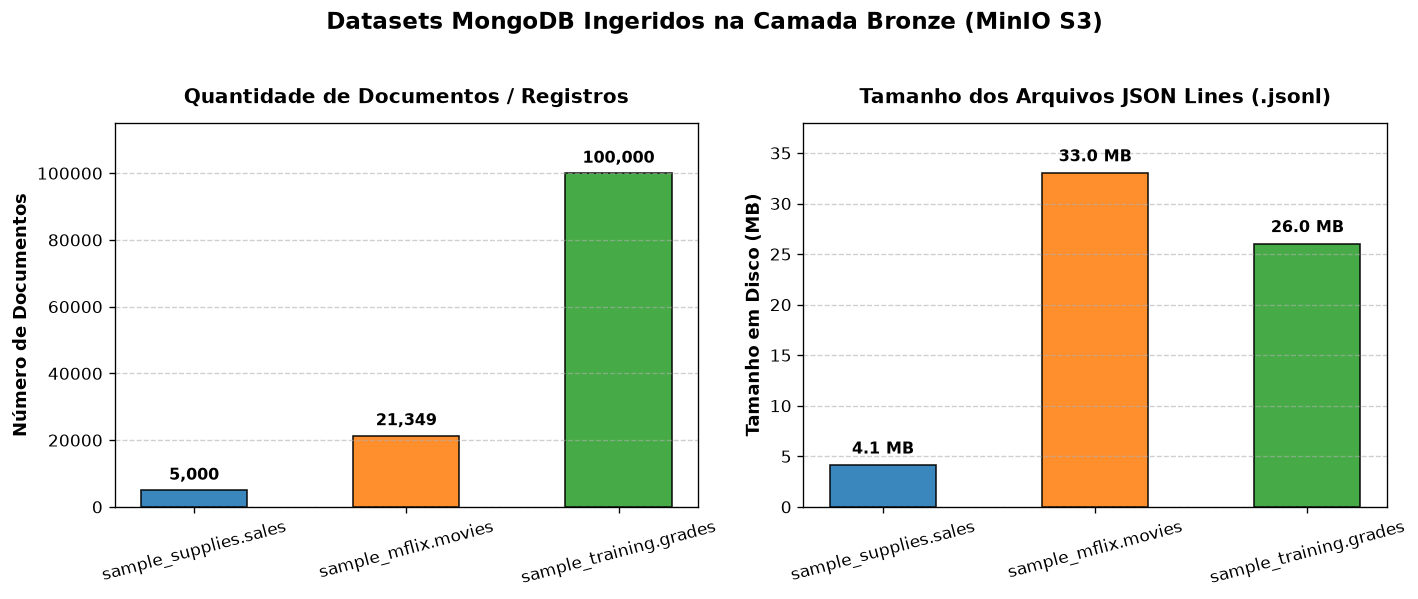

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df_bronze = pd.DataFrame({
    "Banco de Dados": ["sample_supplies", "sample_mflix", "sample_training"],
    "Coleção": ["sales", "movies", "grades"],
    "Documentos": [5000, 21349, 100000],
    "Linhas_JSONL": [5000, 21349, 100000],
    "Tamanho_Host": ["4.1 MB", "33.0 MB", "26.0 MB"],
    "Tamanho_MinIO": ["4.0 MiB", "32.0 MiB", "26.0 MiB"],
    "Chave_S3": [
        "datalake-bronze/mongodb/sample_supplies/sales.jsonl",
        "datalake-bronze/mongodb/sample_mflix/movies.jsonl",
        "datalake-bronze/mongodb/sample_training/grades.jsonl"
    ]
})

colecoes = ["sample_supplies.sales", "sample_mflix.movies", "sample_training.grades"]
docs_count = [5000, 21349, 100000]
size_mb = [4.1, 33.0, 26.0]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.8))

bars1 = ax1.bar(colecoes, docs_count, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', alpha=0.88, width=0.5)
ax1.set_title("Quantidade de Documentos / Registros", fontsize=12, fontweight='bold', pad=12)
ax1.set_ylabel("Número de Documentos", fontsize=10.5, fontweight='bold')
ax1.tick_params(axis='x', rotation=15)
ax1.grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 2000, f"{int(yval):,}", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax1.set_ylim(0, max(docs_count) * 1.15)

bars2 = ax2.bar(colecoes, size_mb, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', alpha=0.88, width=0.5)
ax2.set_title("Tamanho dos Arquivos JSON Lines (.jsonl)", fontsize=12, fontweight='bold', pad=12)
ax2.set_ylabel("Tamanho em Disco (MB)", fontsize=10.5, fontweight='bold')
ax2.tick_params(axis='x', rotation=15)
ax2.grid(axis='y', linestyle='--', alpha=0.6)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.8, f"{yval:.1f} MB", ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax2.set_ylim(0, max(size_mb) * 1.15)

plt.suptitle("Datasets MongoDB Ingeridos na Camada Bronze (MinIO S3)", fontsize=13.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

df_bronze

### Observação Arquitetural (Arquitetura Medallion - Camada Bronze)
- Note que a coleção `sample_mflix.movies` possui **21.349 documentos** e ocupa **33 MB** (`~1,58 KB/doc`, devido a campos textuais extensos como `fullplot`, `cast` e metadados aninhados), enquanto `sample_training.grades` possui **100.000 documentos** mais enxutos e ocupa **26 MB** (`~0,26 KB/doc`).
- A preservação do formato **JSON Lines (`.jsonl`)** na camada **Bronze** (`datalake-bronze/mongodb/<db>/<collection>.jsonl`) garante fidelidade integral ao schema original semiestruturado do MongoDB (incluindo arrays e subdocumentos), desacoplando o banco operacional das futuras transformações analíticas em Spark para as camadas *Silver* (Parquet/Delta) e *Gold*.